<div dir="rtl" align="right">

# 🚀 مشروعنا: نموذج تعلم آلة من بيانات حقيقية (Kaggle)
### دورة الذكاء الاصطناعي وتعلم الآلة — المشروع المنزلي

في هذا الدفتر ستبني **نموذج تعلم آلة كاملاً** من مجموعة بيانات حقيقية اخترتها من Kaggle، وستمر بكل الخطوات التي تعلمتها في الدورة.

## 🗺️ خريطة المشروع
| الخطوة | ماذا ستفعل؟ | بالإنجليزية |
|---|---|---|
| 0 | تجهيز الأدوات | Setup |
| 1 | رفع البيانات وقراءتها | Load Data |
| 2 | استكشاف البيانات | Data Exploration |
| 3 | اختيار الهدف ونوع المهمة | Target & Task |
| 4 | رسم البيانات | Visualization |
| 5 | تنظيف البيانات وتجهيزها | Data Preparation |
| 6 | تقسيم البيانات | Train / Test Split |
| 7 | تدريب النموذج | Training |
| 8 | تقييم النموذج | Evaluation |
| 9 | التنبؤ بمثال جديد | Prediction |
| 10 | أهم الخصائص | Feature Importance |
| 11 | بطاقة المشروع | Project Card |
| 🔵 | تحديات اختيارية للمتقدمين | Challenges |

## 🧩 كيف تعمل في هذا الدفتر؟
* شغّل الخلايا **بالترتيب** بالضغط على ▶ أو **Shift + Enter**.
* في بعض الخلايا ستجد فراغاً مثل `___`. **استبدله بالإجابة الصحيحة** ثم شغّل الخلية.
* فوق كل فراغ يوجد **تلميح**، وإن احتجت مساعدة أكثر اضغط على «💡 تلميح إضافي».
* بعد كل خطوة مهمة توجد رسالة تحقق: ✅ تعني أن عملك صحيح، و❌ تعني أن تراجع الخطوة.
* 🟢 **أساسي**: مطلوب من الجميع. 🔵 **تحدٍّ**: اختياري لمن يريد التعمق.

> ⚠️ **مهم:** Colab يحذف الملفات المرفوعة عند إغلاق الجلسة. إذا عدت لاحقاً، ارفع ملف البيانات مرة أخرى وشغّل الخلايا من البداية (القائمة: **وقت التشغيل ← تشغيل الكل**).

</div>

<div dir="rtl" align="right">

---
# 🟢 الخطوة 0: تجهيز الأدوات (Setup)
شغّل الخلية التالية مرة واحدة. هي تستدعي **المكتبات** التي سنحتاجها، وتجهّز رسائل التحقق.

| المكتبة | دورها |
|---|---|
| **pandas** | قراءة البيانات والتعامل مع الجداول |
| **matplotlib** | الرسم البياني |
| **scikit-learn** (`sklearn`) | النماذج، والتقسيم، والتقييم |

</div>

In [ ]:
# @title ⚙️ شغّلني أولاً
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_error, r2_score, ConfusionMatrixDisplay

pd.set_option("display.max_columns", 50)

def check(condition, ok_message, fail_message):
    """تطبع ✅ إذا كان الشرط صحيحاً، و ❌ مع تلميح إذا لم يكن."""
    if condition:
        print("✅", ok_message)
    else:
        print("❌", fail_message)
    return bool(condition)

def _blank_hint(self, etype, value, tb, tb_offset=None):
    # رسالة واضحة عندما ينسى الطالب ملء فراغ ___
    if "___" in str(value):
        print("🧩 في هذه الخلية فراغ ___ لم يُملأ بعد. اقرأ التلميح فوق الخلية، واستبدل ___ بالإجابة، ثم شغّلها مرة أخرى.")
    elif etype is NameError:
        print("🔁 هذا المتغير غير معرّف بعد: ربما لم تشغّل خلية سابقة، أو فيها فراغ لم تملأه. شغّل الخلايا بالترتيب من البداية.")
        self.showtraceback((etype, value, tb), tb_offset=tb_offset)
    else:
        self.showtraceback((etype, value, tb), tb_offset=tb_offset)

try:
    get_ipython().set_custom_exc((NameError, AttributeError), _blank_hint)
except Exception:
    pass

print("✅ الأدوات جاهزة! انتقل إلى الخطوة 1")

✅ الأدوات جاهزة! انتقل إلى الخطوة 1


<div dir="rtl" align="right">

---
# 🟢 الخطوة 1: رفع البيانات وقراءتها (Load Data)

### أ) ارفع ملف البيانات
شغّل الخلية التالية، ثم اضغط **Choose Files / اختيار ملفات** واختر ملف **CSV** الذي نزّلته من Kaggle (راجع الدليل).

</div>

In [ ]:
# @title 📤 ارفع ملف البيانات (CSV)
try:
    from google.colab import files          # أداة الرفع موجودة في Colab فقط
    uploaded = files.upload()               # تفتح نافذة لاختيار الملف من جهازك
    FILE_NAME = list(uploaded.keys())[0]    # اسم الملف الذي رفعته
except ImportError:
    FILE_NAME = "data.csv"                  # خارج Colab: اكتب اسم الملف هنا

print("📄 اسم الملف:", FILE_NAME)

Saving Student_Performance 3.csv to Student_Performance 3 (1).csv
📄 اسم الملف: Student_Performance 3 (1).csv


<div dir="rtl" align="right">

### ب) اقرأ الملف في جدول
مكتبة pandas فيها دالة تقرأ ملفات **CSV** (ملفات جداول مفصولة بفواصل) وتحوّلها إلى جدول اسمه **DataFrame**.

🧩 **فراغ 1:** ما اسم الدالة التي تقرأ ملف CSV؟ (تبدأ بـ `read_`)

🧩 **فراغ 2 و 3:** اكتب اسم مجموعة البيانات ورابطها في Kaggle (سنحتاجهما في بطاقة المشروع وملف README).

<details><summary>💡 تلميح إضافي</summary>

الدالة اسمها `read_csv` لأنها تقرأ (read) ملف csv.
</details>

</div>

In [ ]:
df = pd.read_csv(FILE_NAME)          # 🧩 فراغ 1: الدالة التي تقرأ ملف CSV

DATASET_NAME = "Student Performance"    # 🧩 فراغ 2: اسم مجموعة البيانات كما في Kaggle
DATASET_URL = "https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression"      # 🧩 فراغ 3: رابط صفحة البيانات في Kaggle

check(isinstance(df, pd.DataFrame), f"قرأنا الملف بنجاح: {len(df)} صفاً", "لم تتم قراءة الملف، راجع فراغ 1")
check(DATASET_NAME.strip("_ ") != "", "اسم مجموعة البيانات مكتوب", "اكتب اسم مجموعة البيانات في فراغ 2")
check("kaggle.com" in DATASET_URL, "رابط Kaggle مكتوب", "انسخ رابط صفحة البيانات من Kaggle في فراغ 3")

✅ قرأنا الملف بنجاح: 10000 صفاً
✅ اسم مجموعة البيانات مكتوب
✅ رابط Kaggle مكتوب


True

<div dir="rtl" align="right">

---
# 🟢 الخطوة 2: استكشاف البيانات (Data Exploration)
قبل أي تدريب، يجب أن **نفهم بياناتنا**: كم صفاً؟ ما الأعمدة؟ هل فيها قيم ناقصة؟

| الأمر | ماذا يعرض؟ |
|---|---|
| `df.head()` | أول 5 صفوف من الجدول |
| `df.shape` | (عدد الصفوف، عدد الأعمدة) |

🧩 **فراغ 4:** الدالة التي تعرض **أول** الصفوف (تعني «رأس» بالإنجليزية).

🧩 **فراغ 5:** الخاصية التي تعطي **شكل** الجدول (عدد الصفوف والأعمدة).

</div>

In [ ]:
print("📐 شكل الجدول (صفوف، أعمدة):", df.head())    # 🧩 فراغ 5
df.shape                                         # 🧩 فراغ 4

📐 شكل الجدول (صفوف، أعمدة):    Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


(10000, 6)

<div dir="rtl" align="right">

### تقرير الأعمدة
الخلية التالية تعطيك تقريراً عن كل عمود. اقرأه جيداً، لأنك ستحتاجه في الخطوتين 3 و 5:
* **النوع:** رقمي (Numerical) أم نصي (Text / Categorical)؟
* **القيم الناقصة:** خلايا فارغة يجب معالجتها.
* **القيم المختلفة:** عمود قيمه كلها مختلفة (مثل الرقم التسلسلي أو الاسم) لا يفيد النموذج غالباً.

</div>

In [ ]:
report = pd.DataFrame({
    "النوع": ["رقمي" if pd.api.types.is_numeric_dtype(df[c]) else "نصي" for c in df.columns],
    "القيم الناقصة": df.isna().sum().values,
    "عدد القيم المختلفة": df.nunique().values,
    "مثال": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
}, index=df.columns)
print(f"عدد الصفوف: {len(df)} | عدد الأعمدة: {df.shape[1]} | مجموع القيم الناقصة: {int(df.isna().sum().sum())}")
report

عدد الصفوف: 10000 | عدد الأعمدة: 6 | مجموع القيم الناقصة: 0


,النوع,القيم الناقصة,عدد القيم المختلفة,مثال
Hours Studied,رقمي,0,9,7
Previous Scores,رقمي,0,60,99
Extracurricular Activities,نصي,0,2,Yes
Sleep Hours,رقمي,0,6,9
Sample Question Papers Practiced,رقمي,0,10,1
Performance Index,رقمي,0,91,91.0


<div dir="rtl" align="right">

---
# 🟢 الخطوة 3: اختيار الهدف ونوع المهمة (Target & Task)

**عمود الهدف (Target)** هو العمود الذي نريد أن يتوقعه النموذج، أي **التسمية (Label)**. باقي الأعمدة هي **الخصائص (Features)**.

### تصنيف أم تنبؤ بقيمة؟ هذا أهم قرار في مشروعك
| | التصنيف (Classification) | التنبؤ بقيمة (Regression) |
|---|---|---|
| **شكل الإجابة** | فئة من خيارات محددة | رقم يمكن أن يأخذ أي قيمة |
| **أمثلة** | نجا / لم ينجُ، فئة سعر الجوال، صالح / غير صالح للشرب | السعر، الدرجة، التكلفة |
| **كيف نقيّم؟** | **الدقة (Accuracy)**: نسبة الإجابات الصحيحة | **متوسط الخطأ (MAE)**: كم يبعد التوقع عن الحقيقة، و **R²**: إلى أي حد يفسّر النموذج البيانات |
| **النماذج** | `...Classifier` | `...Regressor` |

### أعمدة الهدف في مجموعات البيانات المقترحة
| مجموعة البيانات | عمود الهدف | نوع المهمة |
|---|---|---|
| Titanic | `Survived` | تصنيف |
| Mobile Price Classification | `price_range` | تصنيف |
| Water Potability | `Potability` | تصنيف |
| Student Performance | `Performance Index` | تنبؤ بقيمة |
| Housing Prices | `price` | تنبؤ بقيمة |
| Medical Cost (Insurance) | `charges` | تنبؤ بقيمة |

🧩 **فراغ 6:** اكتب اسم عمود الهدف **كما هو مكتوب في الجدول بالضبط** (الحروف الكبيرة والمسافات مهمة).

</div>

In [ ]:
TARGET = "Performance Index"      # 🧩 فراغ 6: اسم عمود الهدف

if check(TARGET in df.columns, f"عمود الهدف «{TARGET}» موجود", "هذا العمود غير موجود. انسخ الاسم من تقرير الأعمدة في الخطوة 2"):
    n_values = df[TARGET].nunique()
    is_text = not pd.api.types.is_numeric_dtype(df[TARGET])
    suggested = "classification" if (is_text or n_values <= 10) else "regression"
    print(f"\n🔎 عمود الهدف فيه {n_values} قيمة مختلفة.")
    print("💡 اقتراحنا:", "تصنيف (classification) لأن الإجابة فئة من خيارات قليلة" if suggested == "classification"
          else "تنبؤ بقيمة (regression) لأن الإجابة رقم بقيم كثيرة")

✅ عمود الهدف «Performance Index» موجود

🔎 عمود الهدف فيه 91 قيمة مختلفة.
💡 اقتراحنا: تنبؤ بقيمة (regression) لأن الإجابة رقم بقيم كثيرة


<div dir="rtl" align="right">

الآن اختر نوع المهمة من القائمة على اليمين، ثم شغّل الخلية. (إن اختلف اختيارك عن الاقتراح ستظهر لك رسالة)

</div>

In [ ]:
# @title 🎯 نوع المهمة
TASK = "regression"  # @param ["classification", "regression"]

TASK_AR = "تصنيف (Classification)" if TASK == "classification" else "تنبؤ بقيمة (Regression)"
check(TASK == suggested, f"اخترت: {TASK_AR}، وهو مناسب لعمود الهدف",
      f"اخترت {TASK_AR}، لكن عمود الهدف يبدو مناسباً لـ {suggested}. فكّر مرة أخرى: هل الإجابة فئة أم رقم؟")

✅ اخترت: تنبؤ بقيمة (Regression)، وهو مناسب لعمود الهدف


True

<div dir="rtl" align="right">

---
# 🟢 الخطوة 4: رسم البيانات (Visualization)
الرسم الأول يُظهر **توزيع عمود الهدف**: في التصنيف نرى عدد كل فئة، وفي التنبؤ بقيمة نرى كيف تتوزع الأرقام.

*عناوين الرسوم بالإنجليزية لأن مكتبة الرسم لا تعرض الحروف العربية بشكل صحيح.*

</div>

🔎 أقل قيمة: 10.0 | أعلى قيمة: 100.0 | المتوسط: 55.2


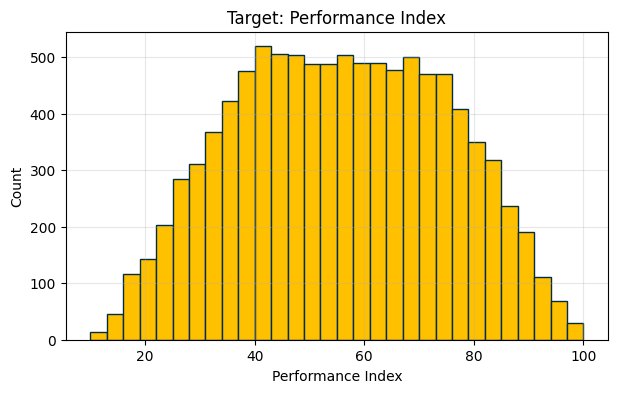

In [ ]:
plt.figure(figsize=(7, 4))
if TASK == "classification":
    df[TARGET].value_counts().sort_index().plot(kind="bar", color="#FFC000", edgecolor="#002D44")
    plt.ylabel("Count")
    counts = df[TARGET].value_counts(normalize=True)
    print(f"🔎 أكبر فئة تمثل {counts.max():.0%} من البيانات.", "البيانات متوازنة تقريباً 👍" if counts.max() < 0.6 else "البيانات غير متوازنة، انتبه لهذا عند قراءة الدقة ⚠️")
else:
    df[TARGET].plot(kind="hist", bins=30, color="#FFC000", edgecolor="#002D44")
    plt.ylabel("Count")
    print(f"🔎 أقل قيمة: {df[TARGET].min():,.1f} | أعلى قيمة: {df[TARGET].max():,.1f} | المتوسط: {df[TARGET].mean():,.1f}")
plt.title(f"Target: {TARGET}"); plt.xlabel(TARGET); plt.grid(alpha=.3); plt.show()

<div dir="rtl" align="right">

### علاقة خاصية واحدة بالهدف
🧩 **فراغ 7:** اختر عموداً تتوقع أنه يؤثر على الهدف (مثل العمر، المساحة، ساعات المذاكرة، الذاكرة RAM…) واكتب اسمه.

</div>

✅ سنرسم العلاقة


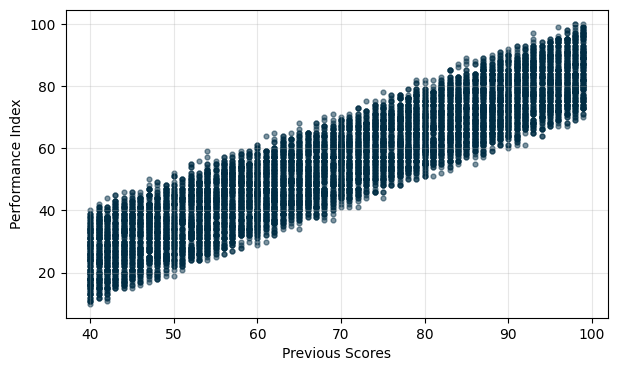

🤔 ماذا تلاحظ؟ هل يبدو أن لهذه الخاصية علاقة بالهدف؟ اكتب ملاحظتك في الخلية النصية التالية.


In [ ]:
FEATURE_TO_PLOT = "Previous Scores"     # 🧩 فراغ 7: اسم عمود تريد رؤية علاقته بالهدف

if check(FEATURE_TO_PLOT in df.columns and FEATURE_TO_PLOT != TARGET, "سنرسم العلاقة", "اكتب اسم عمود موجود وغير عمود الهدف"):
    plt.figure(figsize=(7, 4))
    if TASK == "classification":
        for value in sorted(df[TARGET].dropna().unique())[:6]:
            part = df[df[TARGET] == value][FEATURE_TO_PLOT].dropna()
            if pd.api.types.is_numeric_dtype(part):
                plt.hist(part, bins=25, alpha=.5, label=f"{TARGET}={value}")
            else:
                part.value_counts().plot(kind="bar", alpha=.5, label=f"{TARGET}={value}")
        plt.legend()
    else:
        if pd.api.types.is_numeric_dtype(df[FEATURE_TO_PLOT]):
            plt.scatter(df[FEATURE_TO_PLOT], df[TARGET], s=12, alpha=.5, color="#002D44")
            plt.ylabel(TARGET)
        else:
            df.groupby(FEATURE_TO_PLOT)[TARGET].mean().plot(kind="bar", color="#FFC000", edgecolor="#002D44")
            plt.ylabel(f"mean {TARGET}")
    plt.xlabel(FEATURE_TO_PLOT); plt.grid(alpha=.3); plt.show()
    print("🤔 ماذا تلاحظ؟ هل يبدو أن لهذه الخاصية علاقة بالهدف؟ اكتب ملاحظتك في الخلية النصية التالية.")

<div dir="rtl" align="right">

✍️ **ملاحظتي على الرسم:** (اضغط مرتين هنا واكتب ملاحظتك بجملة أو جملتين)

</div>

<div dir="rtl" align="right">

---
# 🟢 الخطوة 5: تنظيف البيانات وتجهيزها (Data Preparation)
تذكّر: **جودة البيانات أهم من كميتها**. سنجهّز البيانات في 4 مراحل:

| المرحلة | لماذا؟ |
|---|---|
| أ) حذف الأعمدة غير المفيدة | أعمدة مثل الرقم التسلسلي (ID) والاسم لا تساعد النموذج، وقد تجعله يحفظ بدل أن يفهم |
| ب) معالجة القيم الناقصة | النماذج لا تقبل خلايا فارغة |
| ج) فصل الخصائص عن الهدف | `X` = الخصائص، و `y` = الهدف |
| د) تحويل النصوص إلى أرقام | النماذج لا تفهم إلا الأرقام |

### أ) حذف الأعمدة غير المفيدة
الخلية التالية **تقترح** عليك أعمدة قد لا تفيد. أضف ما تراه مناسباً داخل القائمة `DROP_COLUMNS` بين علامتي تنصيص، مثل: `["PassengerId", "Name"]`.
إذا لم يكن هناك أعمدة تريد حذفها، اترك القائمة فارغة `[]`.

</div>

In [ ]:
# 🔎 اقتراحات: أعمدة كل قيمها مختلفة، أو نصوص بقيم كثيرة جداً
for c in df.columns:
    if c == TARGET:
        continue
    if df[c].nunique() == len(df):
        print(f"💡 «{c}»: كل قيمه مختلفة (يشبه رقماً تسلسلياً أو اسماً)")
    elif not pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 30:
        print(f"💡 «{c}»: نص فيه {df[c].nunique()} قيمة مختلفة (صعب الاستفادة منه)")

In [ ]:
DROP_COLUMNS = []      # 🧩 الأعمدة التي تريد حذفها (أو اتركها فارغة)

data = df.drop(columns=[c for c in DROP_COLUMNS if c in df.columns])

# حماية تلقائية: نحذف أي نص بقيم كثيرة جداً لم تحذفه (حتى لا يتضخم الجدول في المرحلة د)
auto_drop = [c for c in data.columns if c != TARGET and not pd.api.types.is_numeric_dtype(data[c]) and data[c].nunique() > 30]
if auto_drop:
    print("🛡️ حذفنا تلقائياً هذه الأعمدة النصية لأن قيمها كثيرة جداً:", auto_drop)
    data = data.drop(columns=auto_drop)
DROPPED = [c for c in DROP_COLUMNS if c in df.columns] + auto_drop

data = data.dropna(subset=[TARGET])          # نحذف الصفوف التي لا يُعرف هدفها
check(TARGET in data.columns, f"بقي {data.shape[1] - 1} عموداً للخصائص", "لا تحذف عمود الهدف!")

✅ بقي 5 عموداً للخصائص


True

<div dir="rtl" align="right">

### ب) معالجة القيم الناقصة (Missing Values)
لكل عمود فيه خلايا فارغة نملؤها بقيمة منطقية:
* **العمود الرقمي** ← نملؤه بـ **الوسيط (Median)**: القيمة التي في المنتصف عند ترتيب الأرقام. أفضل من المتوسط لأنه لا يتأثر بالقيم الشاذة.
* **العمود النصي** ← نملؤه بـ **القيمة الأكثر تكراراً (Mode)**.

🧩 **فراغ 8:** ما اسم الدالة التي تحسب **الوسيط** بالإنجليزية؟

<details><summary>💡 تلميح إضافي</summary>

الوسيط بالإنجليزية Median، والدالة تُكتب بحروف صغيرة.
</details>

</div>

In [ ]:
missing_before = int(data.isna().sum().sum())
FILLED = []
for col in data.columns:
    if data[col].isna().sum() == 0:
        continue
    FILLED.append(col)
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].___())     # 🧩 فراغ 8: الوسيط
    else:
        data[col] = data[col].fillna(data[col].mode()[0])     # القيمة الأكثر تكراراً

print("الأعمدة التي عالجنا قيمها الناقصة:", FILLED if FILLED else "لا يوجد")
check(data.isna().sum().sum() == 0, f"عالجنا {missing_before} قيمة ناقصة ولم يبقَ أي فراغ", "ما زالت هناك قيم ناقصة")

الأعمدة التي عالجنا قيمها الناقصة: لا يوجد
✅ عالجنا 0 قيمة ناقصة ولم يبقَ أي فراغ


True

<div dir="rtl" align="right">

### ج) و د) فصل الخصائص عن الهدف، وتحويل النصوص إلى أرقام
* `X` (حرف كبير) = **الخصائص**: كل الأعمدة ما عدا الهدف.
* `y` (حرف صغير) = **الهدف**.

**تحويل النصوص إلى أرقام (One-Hot Encoding):** الدالة `pd.get_dummies` تحوّل كل عمود نصي إلى أعمدة من 0 و 1. مثلاً عمود «الجنس» يصبح:

| Sex | ← | Sex_male |
|---|---|---|
| male | ← | 1 |
| female | ← | 0 |

🧩 **فراغ 9:** ما المتغير الذي يحمل اسم عمود الهدف؟ (عرّفناه في الخطوة 3)

</div>

In [ ]:
y = data[TARGET]                         # 🧩 فراغ 9: عمود الهدف
X = data.drop(columns=[TARGET])            # الخصائص = كل شيء ما عدا الهدف

text_columns = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
X = pd.get_dummies(X, drop_first=True).astype(float)    # تحويل النصوص إلى أرقام

print("الأعمدة النصية التي حوّلناها إلى أرقام:", text_columns if text_columns else "لا يوجد")
print(f"📐 X: {X.shape[0]} صفاً × {X.shape[1]} خاصية | y: {len(y)} قيمة")
check(TARGET not in X.columns and len(X) == len(y), "الخصائص والهدف جاهزان", "راجع فراغ 9")
X.head()

الأعمدة النصية التي حوّلناها إلى أرقام: ['Extracurricular Activities']
📐 X: 10000 صفاً × 5 خاصية | y: 10000 قيمة
✅ الخصائص والهدف جاهزان


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_Yes
0,7.0,99.0,9.0,1.0,1.0
1,4.0,82.0,4.0,2.0,0.0
2,8.0,51.0,7.0,2.0,1.0
3,5.0,52.0,5.0,2.0,1.0
4,7.0,75.0,8.0,5.0,0.0


<div dir="rtl" align="right">

---
# 🟢 الخطوة 6: تقسيم البيانات (Train / Test Split)
تذكّر التشبيه: **بيانات التدريب = التمارين**، و**بيانات الاختبار = الاختبار النهائي** الذي لا يراه النموذج أثناء التعلم.

| الإعداد | معناه |
|---|---|
| `test_size` | نسبة بيانات الاختبار (0.2 = 20%) |
| `random_state=42` | يجعل التقسيم ثابتاً في كل مرة تشغّل فيها الخلية |
| `stratify` | في التصنيف: يحافظ على نسبة كل فئة في الجزأين |

🧩 **فراغ 10:** اكتب نسبة بيانات الاختبار كرقم عشري. النسبة الشائعة **20%**.

</div>

In [ ]:
TEST_SIZE = 0.2        # 🧩 فراغ 10: نسبة الاختبار (رقم بين 0.1 و 0.4)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=42,
    stratify=y if TASK == "classification" else None,
)
check(0.1 <= TEST_SIZE <= 0.4, f"تدريب: {len(X_train)} صفاً | اختبار: {len(X_test)} صفاً",
      "اختر نسبة بين 0.1 و 0.4، مثل 0.2")

✅ تدريب: 8000 صفاً | اختبار: 2000 صفاً


True

<div dir="rtl" align="right">

---
# 🟢 الخطوة 7: تدريب النموذج (Training)
اختر النموذج من القائمة. كل نموذج له نسخة للتصنيف ونسخة للتنبؤ بقيمة، والخلية تختار النسخة المناسبة لمهمتك تلقائياً:

| النموذج | فكرته باختصار | للتصنيف | للتنبؤ بقيمة |
|---|---|---|---|
| **الغابة العشوائية** (Random Forest) | مئات من أشجار القرار، وكل شجرة «تصوّت»، والأغلبية تفوز. قوي وموثوق | `RandomForestClassifier` | `RandomForestRegressor` |
| **شجرة القرار** (Decision Tree) | سلسلة أسئلة «نعم / لا» كما في اليوم الثاني | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
| **النموذج الخطي** (Linear) | يرسم أفضل خط أو حد فاصل بين البيانات | `LogisticRegression` | `LinearRegression` |

🧩 **فراغ 11:** ما اسم الدالة التي **تدرّب** النموذج؟ (تذكّر: صنع ← ___ ← predict)

</div>

In [ ]:
# @title 🤖 اختر النموذج ودرّبه
MODEL_NAME = "الغابة العشوائية"  # @param ["الغابة العشوائية", "شجرة القرار", "النموذج الخطي"]

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_model(name, task):
    if task == "classification":
        return {"الغابة العشوائية": RandomForestClassifier(n_estimators=200, random_state=42),
                "شجرة القرار": DecisionTreeClassifier(max_depth=5, random_state=42),
                "النموذج الخطي": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}[name]
    return {"الغابة العشوائية": RandomForestRegressor(n_estimators=200, random_state=42),
            "شجرة القرار": DecisionTreeRegressor(max_depth=5, random_state=42),
            "النموذج الخطي": make_pipeline(StandardScaler(), LinearRegression())}[name]

model = make_model(MODEL_NAME, TASK)
model.fit(X_train, y_train)            # 🧩 فراغ 11: التدريب

MODEL_CLASS = type(model[-1] if hasattr(model, "steps") else model).__name__
check(hasattr(model, "predict"), f"تدرّب النموذج: {MODEL_NAME} ({MODEL_CLASS}) على {len(X_train)} مثالاً", "لم يتدرّب النموذج")

✅ تدرّب النموذج: الغابة العشوائية (RandomForestRegressor) على 8000 مثالاً


True

<div dir="rtl" align="right">

---
# 🟢 الخطوة 8: تقييم النموذج (Evaluation)
نعطي النموذج بيانات **الاختبار** التي لم يرها، ونقارن توقعاته بالإجابات الصحيحة.

| المقياس | للمهمة | معناه | الأفضل |
|---|---|---|---|
| **الدقة (Accuracy)** | التصنيف | نسبة التوقعات الصحيحة | كلما **ارتفعت** |
| **مصفوفة الالتباس (Confusion Matrix)** | التصنيف | أين أصاب النموذج وأين أخطأ | الأرقام على القطر |
| **متوسط الخطأ المطلق (MAE)** | التنبؤ بقيمة | كم يبعد التوقع عن الحقيقة في المتوسط | كلما **انخفض** |
| **R²** | التنبؤ بقيمة | إلى أي حد يفسّر النموذج البيانات (1 = مثالي، 0 = مثل التخمين) | كلما اقترب من **1** |

**مرجع التخمين (Baseline):** نقارن نموذجنا بتخمين بسيط جداً (أكثر فئة تكراراً، أو المتوسط). إذا لم يتفوق النموذج على التخمين، فهو لم يتعلم شيئاً مفيداً!

🧩 **فراغ 12:** دالة **التنبؤ**. 🧩 **فراغ 13:** المتغير الذي يحمل **الإجابات الصحيحة** لبيانات الاختبار (عرّفناه في الخطوة 6).

</div>

🎯 متوسط الخطأ المطلق (MAE): 1.81  ← توقعاتنا تبعد عن الحقيقة بهذا المقدار في المتوسط
📈 R² على الاختبار: 0.986 | على التدريب: 0.997
🎲 لو خمّنا دائماً المتوسط سيكون الخطأ: 16.21
✅ نموذجك أفضل من التخمين 👏


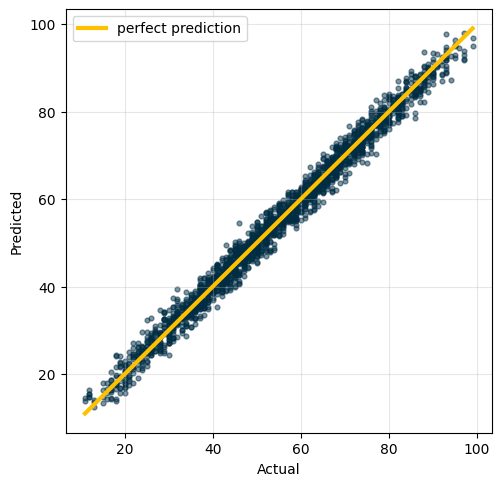

🔎 كلما اقتربت النقاط من الخط الأصفر كانت التوقعات أدق.

👍 الأداء على التدريب والاختبار متقارب: النموذج فهم النمط ولم يحفظ فقط.


In [ ]:
y_pred = model.predict(X_test)            # 🧩 فراغ 12: التنبؤ على بيانات الاختبار
y_true = y_test                           # 🧩 فراغ 13: الإجابات الصحيحة لبيانات الاختبار
RESULTS = {}

if TASK == "classification":
    acc = accuracy_score(y_true, y_pred)                # نقارن الإجابات الصحيحة بالتوقعات
    train_acc = model.score(X_train, y_train)
    baseline = y_test.value_counts(normalize=True).max()   # تخمين أكثر فئة تكراراً
    RESULTS = {"الدقة على الاختبار (Accuracy)": f"{acc:.1%}", "الدقة على التدريب": f"{train_acc:.1%}",
               "مرجع التخمين (Baseline)": f"{baseline:.1%}"}
    print(f"🎯 الدقة على بيانات الاختبار: {acc:.1%}")
    print(f"📚 الدقة على بيانات التدريب: {train_acc:.1%}")
    print(f"🎲 لو خمّنا دائماً أكثر فئة تكراراً: {baseline:.1%}")
    check(acc > baseline, "نموذجك أفضل من التخمين 👏", "نموذجك ليس أفضل من التخمين، راجع البيانات أو جرّب نموذجاً آخر")
    gap = train_acc - acc
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="YlGnBu", colorbar=False)
    plt.title("Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()
else:
    mae = mean_absolute_error(y_true, y_pred)           # متوسط البعد بين الحقيقة والتوقع
    r2 = r2_score(y_test, y_pred)
    train_r2 = model.score(X_train, y_train)
    baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))   # تخمين المتوسط دائماً
    RESULTS = {"متوسط الخطأ المطلق (MAE)": f"{mae:,.2f}", "R² على الاختبار": f"{r2:.3f}",
               "R² على التدريب": f"{train_r2:.3f}", "MAE لو خمّنا المتوسط (Baseline)": f"{baseline_mae:,.2f}"}
    print(f"🎯 متوسط الخطأ المطلق (MAE): {mae:,.2f}  ← توقعاتنا تبعد عن الحقيقة بهذا المقدار في المتوسط")
    print(f"📈 R² على الاختبار: {r2:.3f} | على التدريب: {train_r2:.3f}")
    print(f"🎲 لو خمّنا دائماً المتوسط سيكون الخطأ: {baseline_mae:,.2f}")
    check(mae < baseline_mae, "نموذجك أفضل من التخمين 👏", "نموذجك ليس أفضل من التخمين، راجع البيانات أو جرّب نموذجاً آخر")
    gap = train_r2 - r2
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_test, y_pred, s=12, alpha=.5, color="#002D44")
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    plt.plot(lims, lims, color="#FFC000", lw=3, label="perfect prediction")
    plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.legend(); plt.grid(alpha=.3); plt.show()
    print("🔎 كلما اقتربت النقاط من الخط الأصفر كانت التوقعات أدق.")

OVERFIT = gap > 0.1
print("\n⚠️ الأداء على التدريب أعلى بوضوح من الاختبار: النموذج «حفظ» جزءاً من بيانات التدريب (Overfitting). هذا شائع مع الأشجار، والمهم هو نتيجة الاختبار. للتحسين جرّب التحديين 1 و 2."
      if OVERFIT else "\n👍 الأداء على التدريب والاختبار متقارب: النموذج فهم النمط ولم يحفظ فقط.")

<div dir="rtl" align="right">

✍️ **قراءتي للنتيجة:** (اكتب بجملتين: هل نموذجك جيد؟ ولماذا؟ قارنه بمرجع التخمين)

</div>

<div dir="rtl" align="right">

---
# 🟢 الخطوة 9: التنبؤ بمثال جديد (Prediction)
نأخذ مثالاً من بيانات الاختبار، ونعرض خصائصه، ونقارن توقع النموذج بالإجابة الحقيقية. غيّر رقم المثال بالمنزلق وجرّب.

🧩 **فراغ 14:** دالة التنبؤ مرة أخرى.

</div>

In [ ]:
# @title 🔮 اختر مثالاً
ROW = 0  # @param {type:"slider", min:0, max:50, step:1}

ROW = min(ROW, len(X_test) - 1)
example = X_test.iloc[[ROW]]
original = df.loc[example.index[0]].drop(labels=[TARGET])
prediction = model.predict(example)[0]              # 🧩 فراغ 14
truth = y_test.iloc[ROW]

print("📋 خصائص المثال:")
print(original.to_string())
print("\n🤖 توقع النموذج:", round(prediction, 2) if TASK == "regression" else prediction)
print("✔️ الإجابة الحقيقية:", truth)
if TASK == "classification":
    print("🎉 أصاب!" if prediction == truth else "😅 أخطأ هذه المرة")
else:
    print(f"📏 الفرق: {abs(prediction - truth):,.2f}")

📋 خصائص المثال:
Hours Studied                        5
Previous Scores                     69
Extracurricular Activities          No
Sleep Hours                          8
Sample Question Papers Practiced     2

🤖 توقع النموذج: 56.16
✔️ الإجابة الحقيقية: 51.0
📏 الفرق: 5.16


<div dir="rtl" align="right">

---
# 🟢 الخطوة 10: ما أهم الخصائص؟ (Feature Importance)
أي الخصائص اعتمد عليها النموذج أكثر؟ نخلط قيم كل خاصية عشوائياً ونرى كم ينخفض أداء النموذج: كلما انخفض أكثر، كانت الخاصية أهم. (اسم الطريقة: **Permutation Importance**)

شغّل الخلية فقط (قد تستغرق نصف دقيقة).

</div>

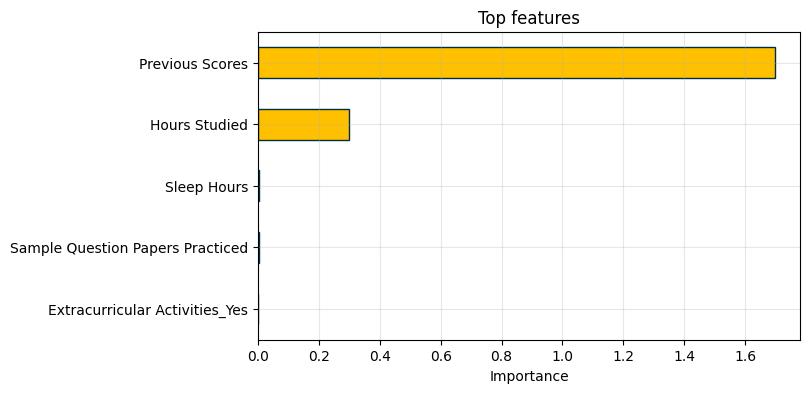

🏆 أهم 5 خصائص: Previous Scores, Hours Studied, Sleep Hours, Sample Question Papers Practiced, Extracurricular Activities_Yes


In [ ]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(min(len(X_test), 1000), random_state=0)
imp = permutation_importance(model, sample, y_test.loc[sample.index], n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
TOP_FEATURES = list(importance.head(5).index)

importance.head(10)[::-1].plot(kind="barh", color="#FFC000", edgecolor="#002D44", figsize=(7, 4))
plt.title("Top features"); plt.xlabel("Importance"); plt.grid(alpha=.3); plt.show()
print("🏆 أهم 5 خصائص:", ", ".join(TOP_FEATURES))

<div dir="rtl" align="right">

✍️ **هل النتيجة منطقية؟** (مثلاً: هل توقعت أن تكون هذه الخاصية مهمة؟)

</div>

<div dir="rtl" align="right">

---
# 🟢 الخطوة 11: بطاقة المشروع (Project Card)
هذه الخلية تجمع **نتائجك الحقيقية** في بطاقة واحدة، وتحفظها في ملف `project_card.md`.

**ستحتاجها لصنع ملف README بمساعدة الذكاء الاصطناعي** (راجع الدليل). الأداة لا تستطيع قراءة مشروعك من الرابط وحده، وقد **تخترع** أرقاماً إن لم تعطها هذه البطاقة!

</div>

In [ ]:
TASK_EN = "Classification" if TASK == "classification" else "Regression"
lines = [
    "## بطاقة المشروع (Project Card)",
    f"- **مجموعة البيانات (Dataset):** {DATASET_NAME}",
    f"- **المصدر (Source):** {DATASET_URL}",
    f"- **حجم البيانات:** {df.shape[0]} صفاً × {df.shape[1]} عموداً",
    f"- **عمود الهدف (Target):** {TARGET}",
    f"- **نوع المهمة (Task):** {TASK_AR}",
    f"- **الأعمدة المحذوفة:** {', '.join(DROPPED) if DROPPED else 'لا يوجد'}",
    f"- **أعمدة عولجت قيمها الناقصة:** {', '.join(FILLED) if FILLED else 'لا يوجد'}",
    f"- **أعمدة نصية حُوّلت إلى أرقام (One-Hot):** {', '.join(text_columns) if text_columns else 'لا يوجد'}",
    f"- **عدد الخصائص بعد التجهيز:** {X.shape[1]}",
    f"- **التقسيم:** تدريب {len(X_train)} صفاً / اختبار {len(X_test)} صفاً ({TEST_SIZE:.0%})",
    f"- **النموذج (Model):** {MODEL_NAME} ({MODEL_CLASS})",
]
lines += [f"- **{k}:** {v}" for k, v in RESULTS.items()]
lines += [
    f"- **حفظ أم فهم؟** {'فرق كبير بين التدريب والاختبار (احتمال Overfitting)' if OVERFIT else 'الأداء متقارب على التدريب والاختبار'}",
    f"- **أهم 5 خصائص (Top Features):** {', '.join(TOP_FEATURES)}",
    "- **الأدوات:** Python, pandas, scikit-learn, matplotlib, Google Colab",
]
CARD = "\n".join(lines)
with open("project_card.md", "w", encoding="utf-8") as f:
    f.write(CARD)
print(CARD)
print("\n💾 حفظنا البطاقة في الملف project_card.md (تجده في قائمة الملفات 📁 على يسار Colab)")

## بطاقة المشروع (Project Card)
- **مجموعة البيانات (Dataset):** Student Performance
- **المصدر (Source):** https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression
- **حجم البيانات:** 10000 صفاً × 6 عموداً
- **عمود الهدف (Target):** Performance Index
- **نوع المهمة (Task):** تنبؤ بقيمة (Regression)
- **الأعمدة المحذوفة:** لا يوجد
- **أعمدة عولجت قيمها الناقصة:** لا يوجد
- **أعمدة نصية حُوّلت إلى أرقام (One-Hot):** Extracurricular Activities
- **عدد الخصائص بعد التجهيز:** 5
- **التقسيم:** تدريب 8000 صفاً / اختبار 2000 صفاً (20%)
- **النموذج (Model):** الغابة العشوائية (RandomForestRegressor)
- **متوسط الخطأ المطلق (MAE):** 1.81
- **R² على الاختبار:** 0.986
- **R² على التدريب:** 0.997
- **MAE لو خمّنا المتوسط (Baseline):** 16.21
- **حفظ أم فهم؟** الأداء متقارب على التدريب والاختبار
- **أهم 5 خصائص (Top Features):** Previous Scores, Hours Studied, Sleep Hours, Sample Question Papers Practiced, Extracurricular Activities_Yes
- **الأدوات:** Python, pandas, 

<div dir="rtl" align="right">

**انسخ البطاقة كاملة** (من «## بطاقة المشروع» إلى آخر سطر)، فستلصقها في أمر README كما في الدليل.

لتنزيل ملف البطاقة إلى جهازك، شغّل الخلية التالية (اختياري).

</div>

In [ ]:
try:
    from google.colab import files
    files.download("project_card.md")
except ImportError:
    print("التنزيل يعمل داخل Colab فقط")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="rtl" align="right">

---
# ✅ فحص المشروع
شغّل هذه الخلية للتأكد أنك أنهيت كل الخطوات الأساسية قبل الرفع إلى GitHub.

</div>

In [ ]:
steps = {
    "1. قراءة البيانات": "df" in globals(),
    "3. اختيار الهدف": "TARGET" in globals() and TARGET in df.columns,
    "5. تجهيز البيانات": "X" in globals() and "y" in globals(),
    "6. التقسيم": "X_test" in globals(),
    "7. التدريب": "model" in globals() and hasattr(model, "predict"),
    "8. التقييم": "y_pred" in globals() and bool(RESULTS),
    "10. أهم الخصائص": "TOP_FEATURES" in globals(),
    "11. بطاقة المشروع": "CARD" in globals(),
}
for name, done in steps.items():
    print("✅" if done else "⬜", name)
print("\n🎉 أحسنت! مشروعك جاهز للرفع إلى GitHub (راجع الدليل)" if all(steps.values()) else "\n⬆️ أكمل الخطوات الناقصة أولاً")

✅ 1. قراءة البيانات
✅ 3. اختيار الهدف
✅ 5. تجهيز البيانات
✅ 6. التقسيم
✅ 7. التدريب
✅ 8. التقييم
✅ 10. أهم الخصائص
✅ 11. بطاقة المشروع

🎉 أحسنت! مشروعك جاهز للرفع إلى GitHub (راجع الدليل)


<div dir="rtl" align="right">

---
# 🔵 تحديات اختيارية (للمتقدمين)
أنهيت المسار الأساسي؟ هذه تحديات تجعل مشروعك أقوى وتميّزك. **أعد تشغيل الخطوة 11 بعد أي تحسين** لتحديث بطاقة المشروع.

## 🔵 التحدي 1: قارن بين النماذج الثلاثة
أي نموذج يعطي أفضل نتيجة على بياناتك؟ `model.score` تعطي **الدقة** في التصنيف و **R²** في التنبؤ بقيمة (الأعلى أفضل في الحالتين).

🧩 أكمل الفراغين: دالة التدريب، ودالة حساب النتيجة.

</div>

In [ ]:
comparison = {}
for name in ["الغابة العشوائية", "شجرة القرار", "النموذج الخطي"]:
    m = make_model(name, TASK)
    m.fit(X_train, y_train)                     # 🧩 التدريب
    comparison[name] = {"التدريب": m.score(X_train, y_train), "الاختبار": m.score(X_test, y_test)}   # 🧩 النتيجة

table = pd.DataFrame(comparison).T.sort_values("الاختبار", ascending=False).round(3)
print("🏆 أفضل نموذج على الاختبار:", table.index[0])
table

🏆 أفضل نموذج على الاختبار: النموذج الخطي


,التدريب,الاختبار
النموذج الخطي,0.989,0.989
الغابة العشوائية,0.997,0.986
شجرة القرار,0.964,0.965


<div dir="rtl" align="right">

## 🔵 التحدي 2: قلّل الحفظ (Overfitting) بضبط عمق الشجرة
`max_depth` يحدد عدد مستويات الأسئلة في الشجرة. شجرة عميقة جداً تحفظ، وشجرة سطحية جداً لا تتعلم بما يكفي. ابحث عن **العمق الأفضل**.

🧩 أكمل الفراغ: المتغير الذي يحمل العمق الحالي داخل الحلقة.

</div>

In [ ]:
depths = range(1, 21)
train_scores, test_scores = [], []
for d in depths:
    Model = RandomForestClassifier if TASK == "classification" else RandomForestRegressor
    m = Model(n_estimators=100, max_depth=___, random_state=42)      # 🧩 العمق الحالي
    m.fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))

best_depth = list(depths)[int(np.argmax(test_scores))]
plt.figure(figsize=(7, 4))
plt.plot(depths, train_scores, "o-", color="#FFC000", label="train")
plt.plot(depths, test_scores, "o-", color="#002D44", label="test")
plt.axvline(best_depth, ls="--", color="gray"); plt.xlabel("max_depth"); plt.ylabel("score"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"🏆 أفضل عمق: {best_depth} (نتيجة الاختبار {max(test_scores):.3f})")

<div dir="rtl" align="right">

💡 لتطبيق أفضل عمق على نموذجك: في الخطوة 7 استبدل `RandomForestClassifier(n_estimators=200, random_state=42)` بـ `RandomForestClassifier(n_estimators=200, max_depth=أفضل_عمق, random_state=42)` (أو Regressor)، ثم أعد تشغيل الخطوات 7 إلى 11.

## 🔵 التحدي 3: التحقق المتقاطع (Cross-Validation)
بدل تقسيم واحد للتدريب والاختبار، نقسم البيانات إلى **5 أجزاء**، ونجعل كل جزء مرة للاختبار. النتيجة أكثر ثقة لأنها لا تعتمد على حظ تقسيم واحد.

🧩 أكمل الفراغ: عدد الأجزاء (cv).

</div>

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(make_model(MODEL_NAME, TASK), X, y, cv=___)      # 🧩 عدد الأجزاء
print("نتيجة كل جزء:", np.round(scores, 3))
print(f"📊 المتوسط: {scores.mean():.3f} ± {scores.std():.3f}")
print("🔎 إذا كانت النتائج متقاربة فنموذجك مستقر وموثوق.")

<div dir="rtl" align="right">

## 🔵 التحدي 4: فكرتك أنت (هندسة الخصائص — Feature Engineering)
اصنع **خاصية جديدة** من الخصائص الموجودة قد تساعد النموذج، ثم أعد التدريب وقارن. أمثلة:
* **Titanic:** `FamilySize = SibSp + Parch + 1` (حجم العائلة).
* **Housing:** `area_per_room = area / bedrooms` (المساحة لكل غرفة).
* **Mobile:** `screen_area = sc_h * sc_w` (مساحة الشاشة).
* **Medical Cost:** `is_obese = bmi > 30`.

أضف الخاصية على `df` بعد الخطوة 1 مباشرة، ثم أعد تشغيل كل الخطوات. هل تحسّنت النتيجة؟

</div>

In [ ]:
# ✍️ اكتب كودك هنا، مثال:
# df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

<div dir="rtl" align="right">

---
# 🏁 الخطوة الأخيرة: احفظ عملك وارفعه إلى GitHub
1. من القائمة: **ملف ← تنزيل ← تنزيل ملف ‎.ipynb** (احفظ الدفتر بعد تشغيله ليظهر فيه كل شيء).
2. اتبع خطوات **الرفع إلى GitHub** وصنع **README** في الدليل.

بالتوفيق! 🚀

</div>